# problem 3

## 1 imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from typing import List, Tuple
from sklearn.metrics import mean_squared_error
from dataloader import HW2Dataset
from plotting import plot_surface_2d
%config InlineBackend.figure_format = 'retina'

np.random.seed(42)
torch.manual_seed(42);

## 2 data and split shapes

In [ ]:
data = HW2Dataset.from_csv("train.csv", "val.csv", "test.csv")

X_train, y_train = data.train.X, data.train.y
X_val, y_val = data.val.X, data.val.y
X_test = data.test.X

pd.DataFrame({
    "split": ["train", "validation", "test"],
    "features": [X_train.shape, X_val.shape, X_test.shape],
    "targets": [y_train.shape, y_val.shape, None]
})

,split,features,targets
0,train,"(600, 2)","(600,)"
1,validation,"(200, 2)","(200,)"
2,test,"(200, 2)",None


## 3 part a training data visualization

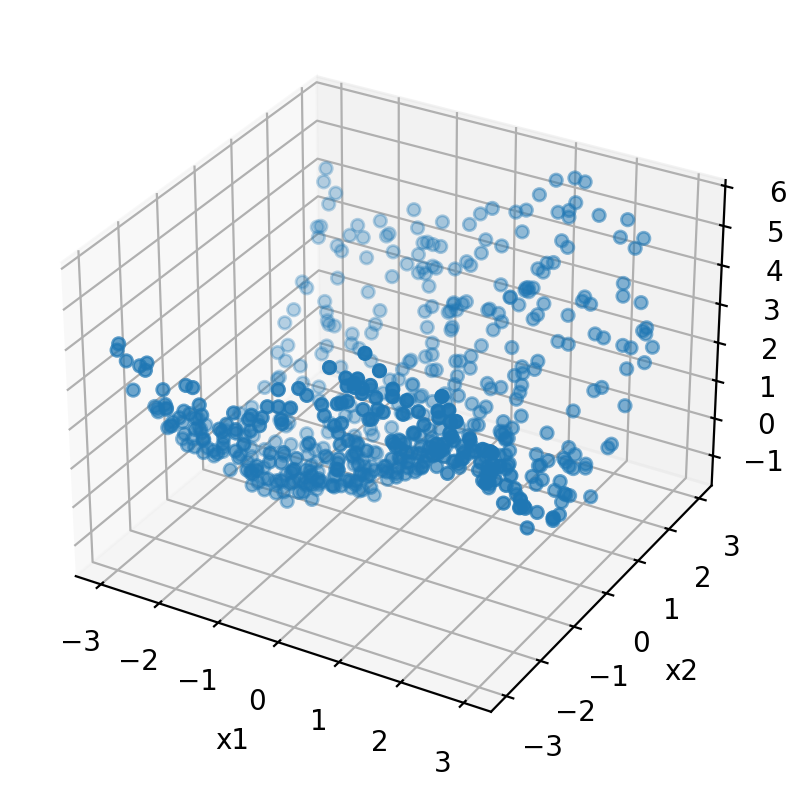

In [ ]:
x1 = X_train[:, 0]
x2 = X_train[:, 1]

fig = plt.figure()
ax = fig.add_subplot(projection="3d")

ax.scatter(x1, x2, y_train)
ax.set(xlabel="x1", ylabel="x2", zlabel="y")

plt.show()

## 4 part b rks model

$$
\phi_j^{\sin}(x_i) = \sin(w_j^T x_i + b_j), \quad
\phi_j^{\cos}(x_i) = \cos(w_j^T x_i + b_j),
$$
and
$$
z_i = \bigl(\phi_1^{\sin}(x_i), \phi_1^{\cos}(x_i), \ldots, \phi_h^{\sin}(x_i), \phi_h^{\cos}(x_i)\bigr)^\top \in \mathbb{R}^{2h}.
$$

In [ ]:
class RandomKitchenSinks:
    def __init__(self, D: int = 1000, sigma: float = 1.0, ridge_lambda: float = 1e-3):
        self.D = D
        self.sigma = sigma
        self.ridge_lambda = ridge_lambda

        h = D // 2
        self.W = np.random.normal(0, 1 / sigma, size=(2,h))
        self.b = np.random.uniform(0, 2 * np.pi, size=h)

    def _features(self, X: np.ndarray) -> np.ndarray:
      angles = X @ self.W + self.b
      return np.concatenate(
          [np.sin(angles), np.cos(angles)],
          axis=1
      )

    def fit(self, X: np.ndarray, y: np.ndarray):
        phi = self._features(X)
        # Now we want
        A = phi.T @ phi + self.ridge_lambda * np.eye(self.D)
        self.coef_ = np.linalg.solve(A, phi.T @ y)
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        phi = self._features(X)
        return phi @ self.coef_

In [ ]:
rks = RandomKitchenSinks(D=100)
rks.fit(X_train, y_train)

train_mse = mean_squared_error(y_train, rks.predict(X_train))
val_mse = mean_squared_error(y_val, rks.predict(X_val))

print("training mse", train_mse)
print("validation mse", val_mse)

training mse 0.0303670125551925
validation mse 0.03862403640544346


## 5 part b hyperparameter sweep and mse plots

In [ ]:
def sweep_rks_model(sweep_D, X_train, y_train, X_val, y_val):
    results = []

    for D in sweep_D:
        model = RandomKitchenSinks(D=D)
        model.fit(X_train, y_train)

        results.append({
            "D": D,
            "train_mse": mean_squared_error(y_train, model.predict(X_train)),
            "val_mse": mean_squared_error(y_val, model.predict(X_val))
        })

    return pd.DataFrame(results)

In [ ]:
np.random.seed(42)

rks_results = sweep_rks_model(
    [10, 20, 50, 100, 200, 500, 1000],
    X_train, y_train, X_val, y_val
)

rks_results

,D,train_mse,val_mse
0,10,1.475116,1.296759
1,20,0.054882,0.048103
2,50,0.031140,0.037880
3,100,0.030318,0.039593
4,200,0.029942,0.039590
5,500,0.029055,0.044542
6,1000,0.028898,0.044647


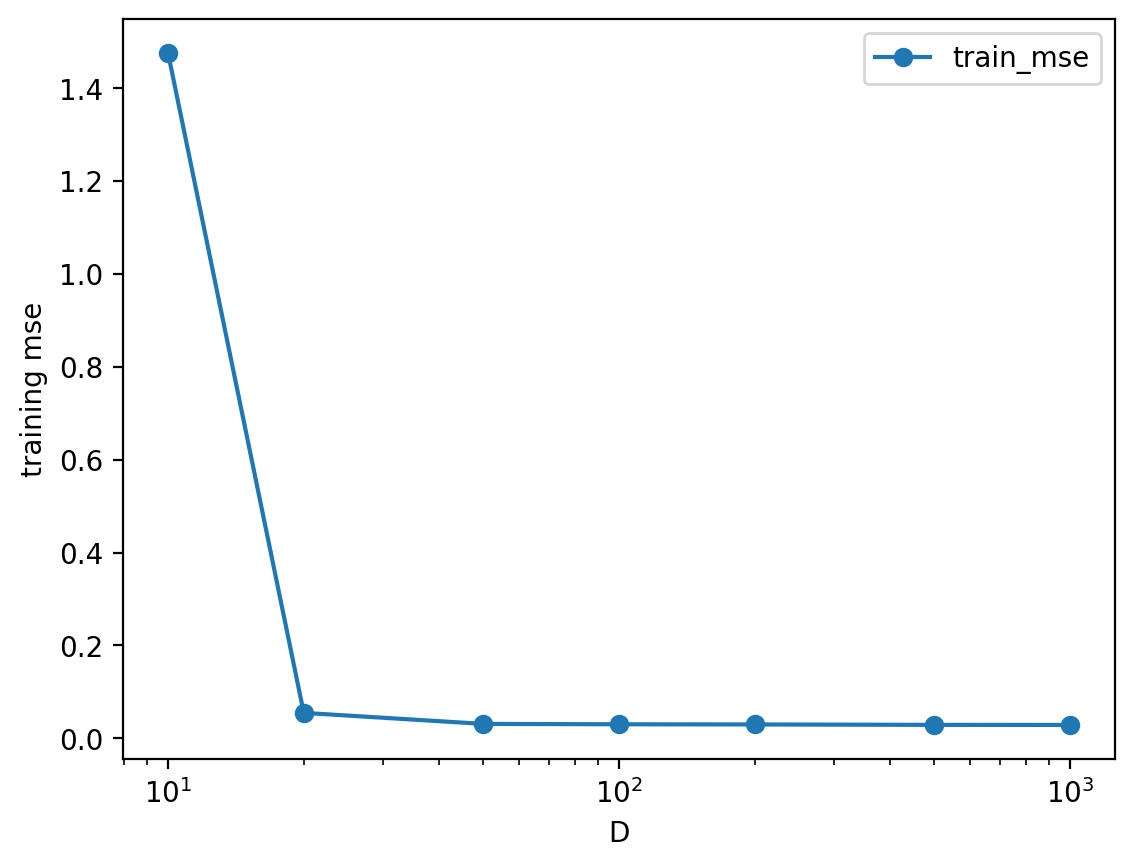

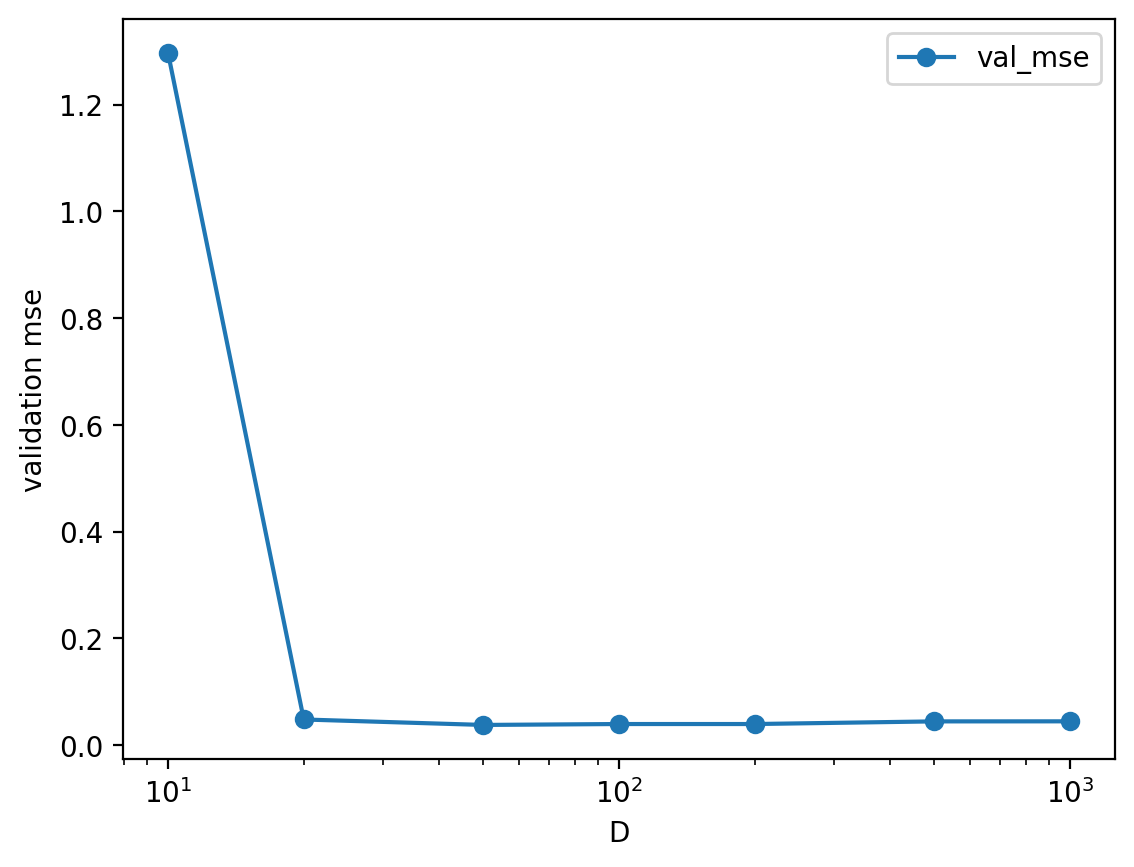

In [ ]:
rks_results.plot(x="D", y="train_mse", marker="o", logx=True)
plt.ylabel("training mse")
plt.show()

rks_results.plot(x="D", y="val_mse", marker="o", logx=True)
plt.ylabel("validation mse")
plt.show()

In [ ]:
# df[col].idxmin() index of min val of
#loc(index, column) -> val
best_rks_D = int(rks_results.loc[rks_results["val_mse"].idxmin(), "D"])

## 6 part c one hidden layer mlp

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

In [ ]:
class MLP(nn.Module):
    def __init__(self, d_in: int, d_hidden: int = 128, d_out: int = 1,
                 lr: float = 1e-3, batch_size: int = 128, activation: str = "relu"):
        super().__init__()

        self.lr = lr
        self.batch_size = batch_size

        self.net = nn.Sequential(
            nn.Linear(d_in, d_hidden),
            nn.ReLU(),
            nn.Linear(d_hidden, d_out)
        )

    def fit(self, X, y, epochs=500):
        X = torch.from_numpy(X).float()
        y = torch.from_numpy(y).float().view(-1, 1)

        loader = DataLoader(
            TensorDataset(X, y),
            batch_size=self.batch_size,
            shuffle=True
        )

        optimizer = torch.optim.Adam(self.parameters(), lr=self.lr)
        loss_fn = nn.MSELoss()

        self.train()

        for epoch in range(epochs):
            for X_batch, y_batch in loader:
                optimizer.zero_grad()
                predictions = self(X_batch)
                loss = loss_fn(predictions, y_batch)
                loss.backward()
                optimizer.step()

        return self

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        return self.net(X)

    def predict(self, X: np.ndarray) -> np.ndarray:
        with torch.no_grad():
            X = torch.from_numpy(X).float()
            return self.forward(X).detach().numpy()

In [ ]:
torch.manual_seed(42)

mlp = MLP(d_in=2, d_hidden=128)
mlp.fit(X_train, y_train)

train_mse = mean_squared_error(y_train, mlp.predict(X_train))
val_mse = mean_squared_error(y_val, mlp.predict(X_val))

print("training mse", train_mse)
print("validation mse", val_mse)

training mse 0.03202993662302685
validation mse 0.039575947534410134


## 7 part c hyperparameter sweep and mse plots

In [ ]:
def mlp_sweep(sweep_values, X_train, y_train, X_val, y_val):
    results = []

    for d_hidden in sweep_values:
        torch.manual_seed(42)

        model = MLP(d_in=2, d_hidden=d_hidden)
        model.fit(X_train, y_train)

        results.append({
            "d_hidden": d_hidden,
            "train_mse": mean_squared_error(y_train, model.predict(X_train)),
            "val_mse": mean_squared_error(y_val, model.predict(X_val))
        })

    return pd.DataFrame(results)

In [ ]:
mlp_results = mlp_sweep(
    [16, 32, 64, 128, 256],
    X_train, y_train, X_val, y_val
)

mlp_results

,d_hidden,train_mse,val_mse
0,16,0.116737,0.124909
1,32,0.044910,0.049892
2,64,0.036005,0.043248
3,128,0.032030,0.039576
4,256,0.030208,0.038366


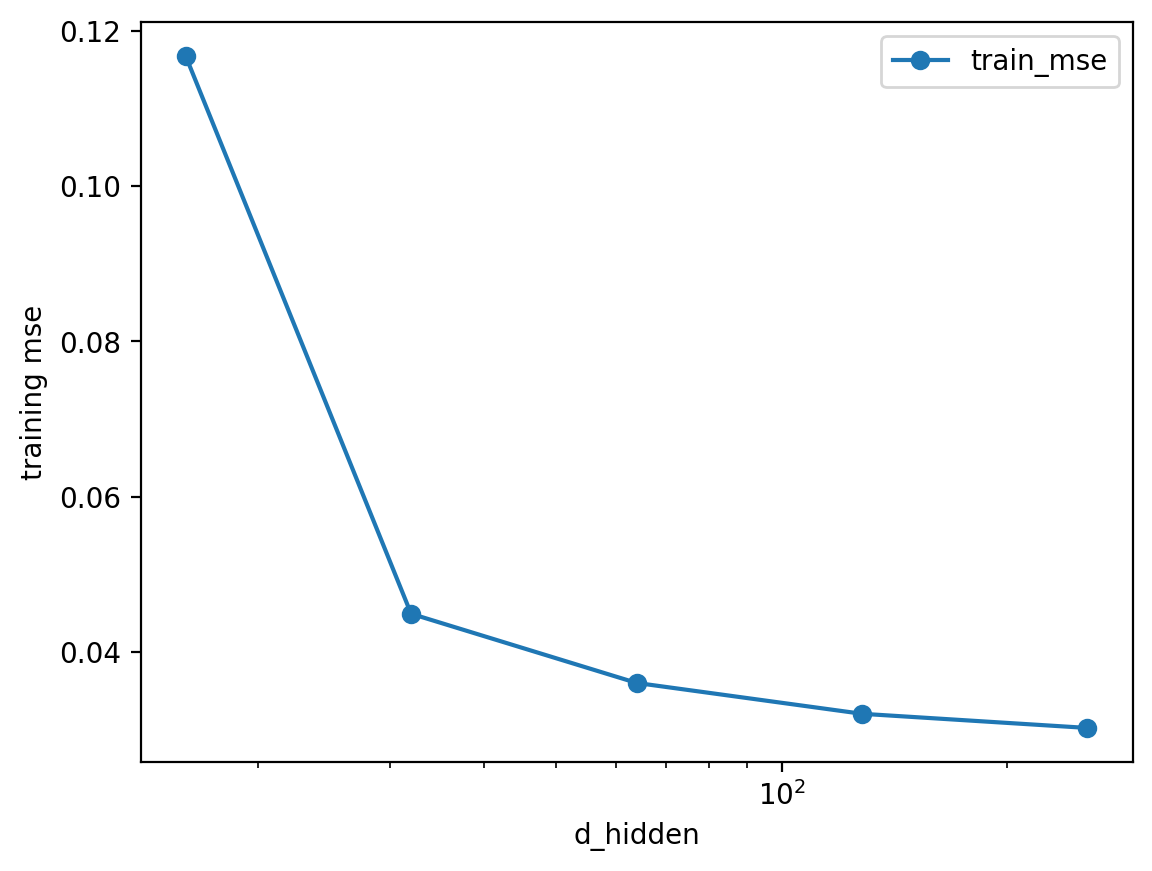

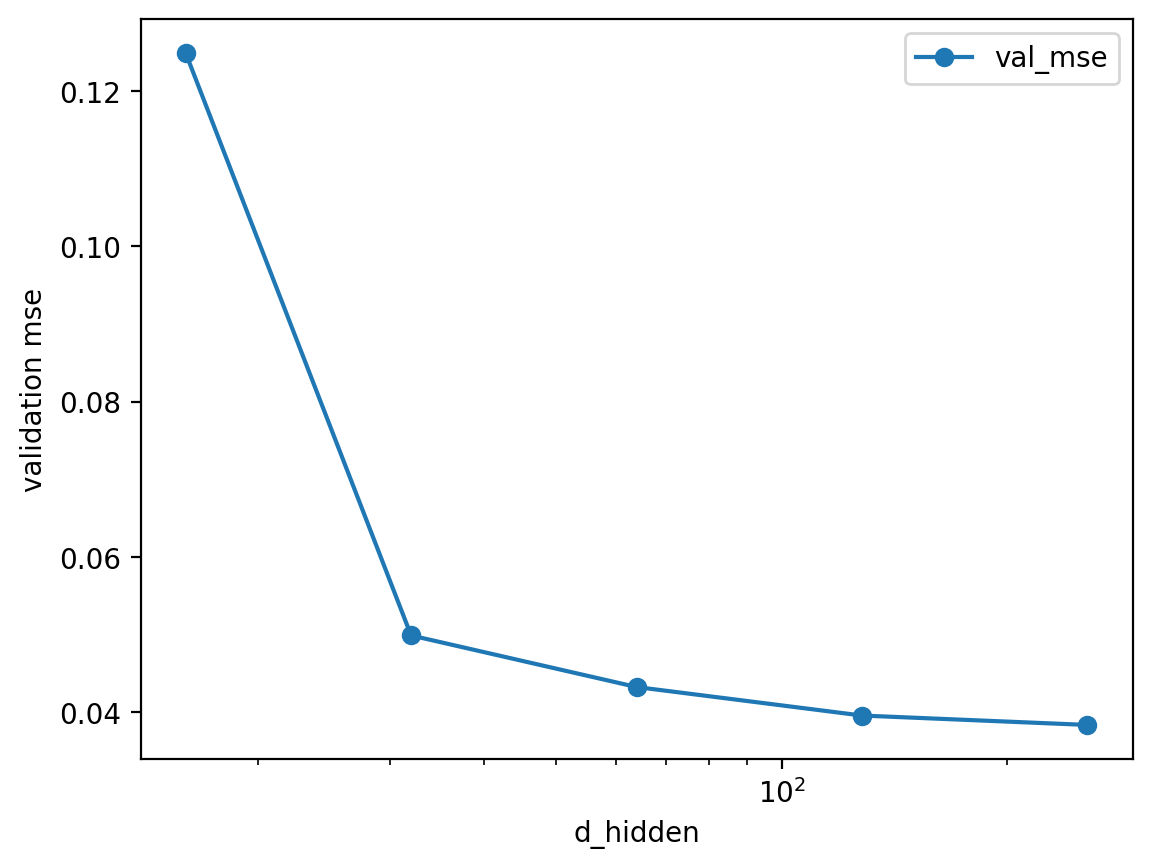

In [ ]:
mlp_results.plot(x="d_hidden", y="train_mse", marker="o", logx=True)
plt.ylabel("training mse")
plt.show()

mlp_results.plot(x="d_hidden", y="val_mse", marker="o", logx=True)
plt.ylabel("validation mse")
plt.show()

best_mlp_hidden = int(
    mlp_results.loc[mlp_results["val_mse"].idxmin(), "d_hidden"]
)

## 8 part d refit and validation comparison

In [ ]:
np.random.seed(42)
best_rks = RandomKitchenSinks(D=best_rks_D)
best_rks.fit(X_train, y_train)

torch.manual_seed(42)
best_mlp = MLP(d_in=2, d_hidden=best_mlp_hidden)
best_mlp.fit(X_train, y_train)

comparison = pd.DataFrame({
    "model": ["rks", "mlp"],
    "val_mse": [
        mean_squared_error(y_val, best_rks.predict(X_val)),
        mean_squared_error(y_val, best_mlp.predict(X_val))
    ]
})

comparison

,model,val_mse
0,rks,0.036785
1,mlp,0.038366


## 9 part d test predictions

In [ ]:
rks_predictions_path = "rks_test_predictions.csv"
mlp_predictions_path = "mlp_test_predictions.csv"

rks_test_predictions = best_rks.predict(X_test).ravel()
mlp_test_predictions = best_mlp.predict(X_test).ravel()

np.savetxt(rks_predictions_path, rks_test_predictions, delimiter=",")
np.savetxt(mlp_predictions_path, mlp_test_predictions, delimiter=",")

print(rks_test_predictions.shape, mlp_test_predictions.shape)

(200,) (200,)


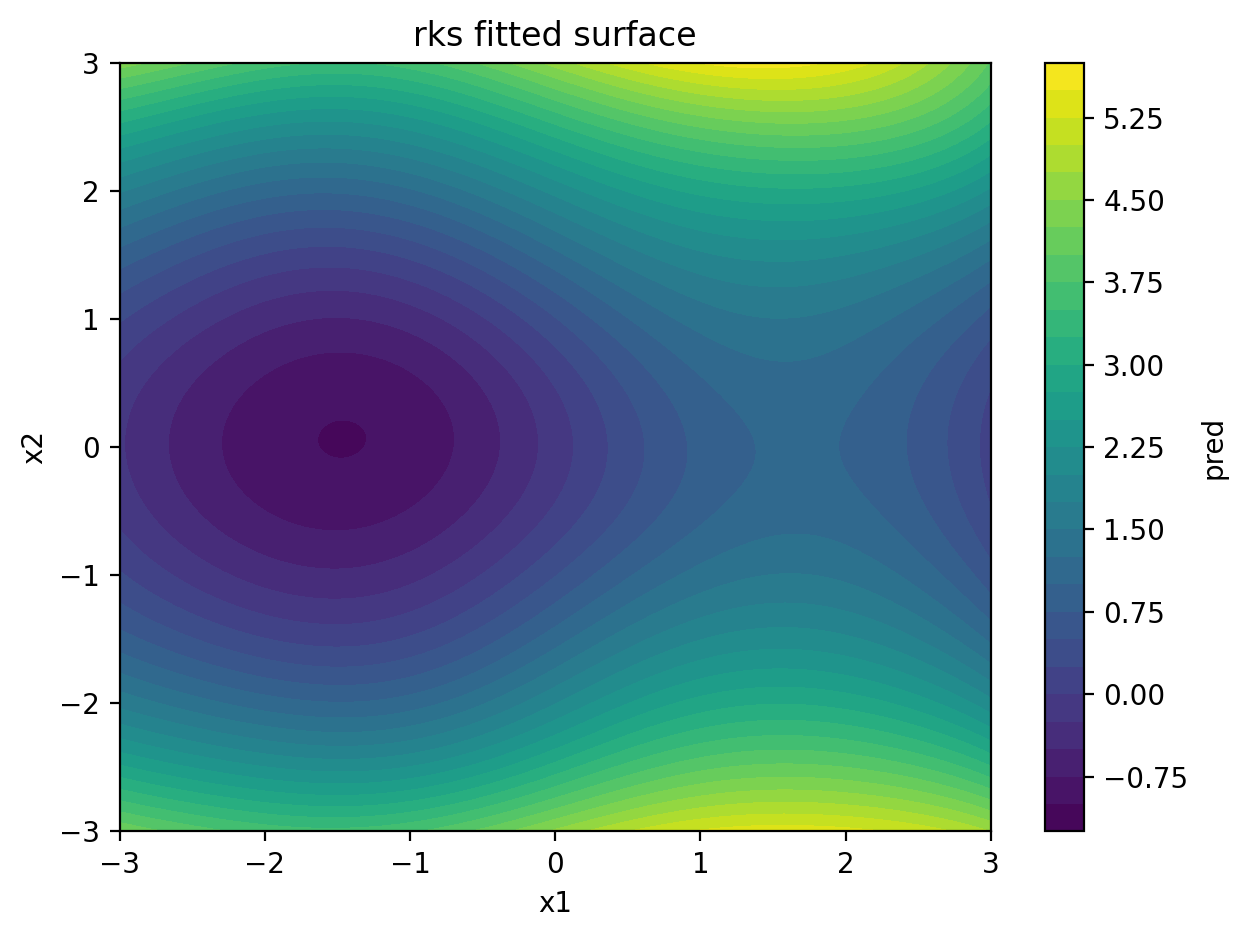

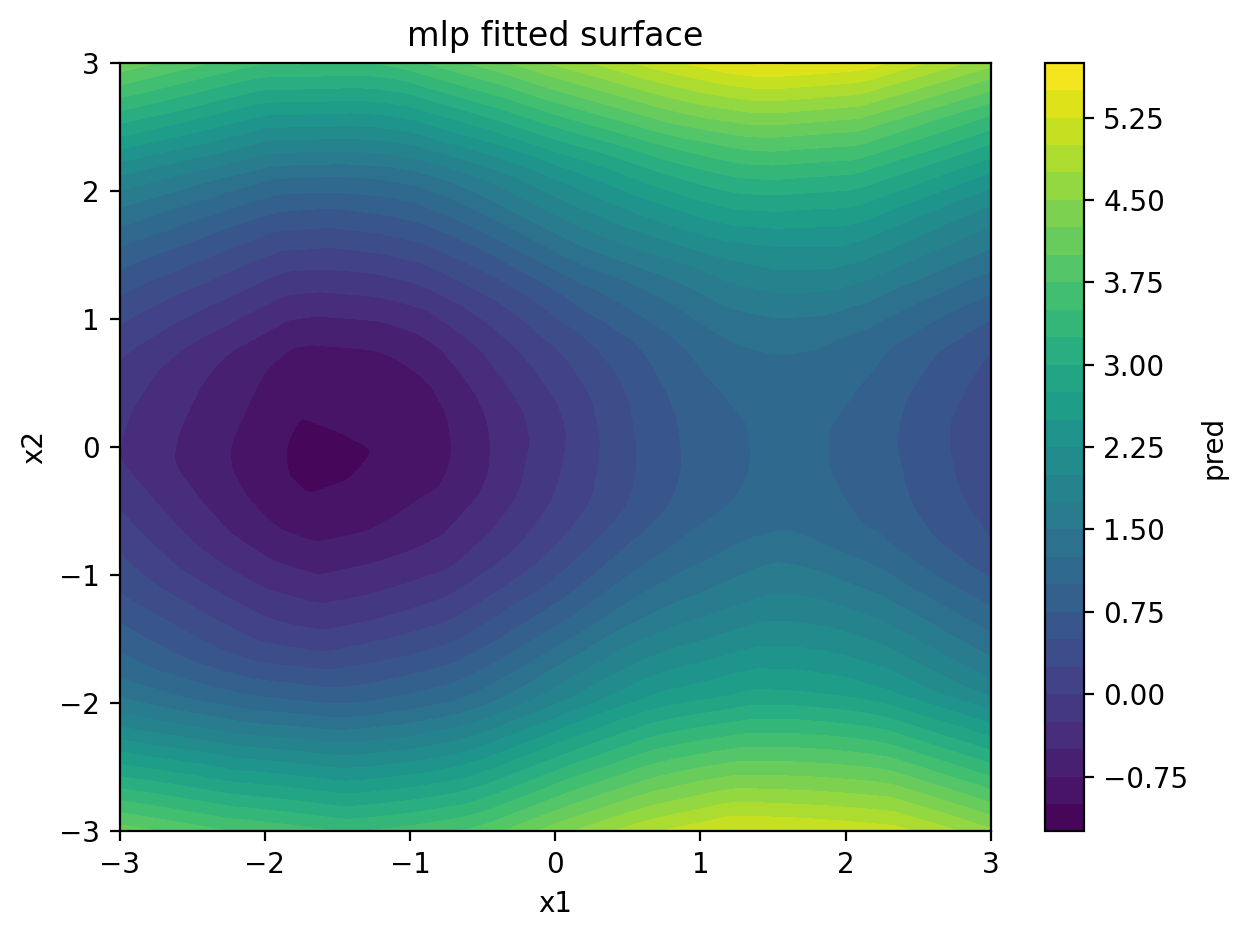

## 10 part d fitted surfaces and comparison

In [ ]:
from google.colab import files

files.download(rks_predictions_path)
files.download(mlp_predictions_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plot_surface_2d(
    best_rks.predict, (-3, 3), (-3, 3),
    title="rks fitted surface",
    filename="rks_surface.png"
)
plt.show()

plot_surface_2d(
    best_mlp.predict, (-3, 3), (-3, 3),
    title="mlp fitted surface",
    filename="mlp_surface.png"
)
plt.show()